### Лабораторная работа №1

### Васильев Артём

### Группа 6231

## Анализ медицинских данных

1. Считать csv файл с данными.
    *   [Ссылка на файл](https://drive.google.com/file/d/12HHlCr_yO8bx6icKqEs7N2QBt8fqOHYS/)
    *   Столбец для предсказания ***stroke***
2. Провести первичный анализ данных (количество признаков, пропуски, распределение признаков и т.д.). Визуализировать результаты.
3. Провести очистку и подготовку данных для обучения (балансировка, разбиение, кодировка вектора признаков).
4. Обучить классические ML модели.
    *   наивный байесовский
    *   логистическая регрессия
    *   дерево решений
    *   случайный лес/бустинг
5. Построить небольшую нейронную сеть и обучить её.

  
    
    
*Для работы можно использовать любые библиотеки, кроме готовых AutoML фреймворков*
  
  
  

---



>  
По всем вопросам писать на почту  ***cybersouls@yandex.ru*** или в ЛС в [VK](https://vk.ru/id174122634)/[tg](https://t.me/volfgunus)

## 0. Импорт библиотек

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.utils import resample
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams['figure.dpi'] = 100

## 1. Загрузка данных

In [2]:
df = pd.read_csv('AMD1.csv')
print('Размер датасета:', df.shape)
df.head()

Размер датасета: (5110, 14)


,id,gender,age,birthplace,birthmonth,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,Buenos Aires,May,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,Shanghai,Dec,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,Moscow,Nov,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,Manila,Mar,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,Tehran,Apr,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 2. Первичный анализ данных
### 2.1 Общая информация: признаки, типы, пропуски, дубликаты

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   birthplace         5110 non-null   object 
 4   birthmonth         5110 non-null   object 
 5   hypertension       5110 non-null   int64  
 6   heart_disease      5110 non-null   int64  
 7   ever_married       5110 non-null   object 
 8   work_type          5110 non-null   object 
 9   Residence_type     5110 non-null   object 
 10  avg_glucose_level  5110 non-null   float64
 11  bmi                4909 non-null   float64
 12  smoking_status     3566 non-null   object 
 13  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(7)
memory usage: 559.0+ KB


In [4]:
TARGET = 'stroke'
num_features = ['age', 'avg_glucose_level', 'bmi']
bin_features = ['hypertension', 'heart_disease']
cat_features = ['gender', 'birthplace', 'birthmonth', 'ever_married',
                'work_type', 'Residence_type', 'smoking_status']

print(f'Всего признаков (без id и целевого): {df.shape[1] - 2}')
print(f'  числовых: {len(num_features)}, бинарных: {len(bin_features)}, категориальных: {len(cat_features)}')
print('Полных дубликатов строк:', df.duplicated().sum())
print('Дубликатов id:', df['id'].duplicated().sum())

Всего признаков (без id и целевого): 12
  числовых: 3, бинарных: 2, категориальных: 7
Полных дубликатов строк: 0
Дубликатов id: 0


,пропусков,"доля, %"
bmi,201,3.93
smoking_status,1544,30.22


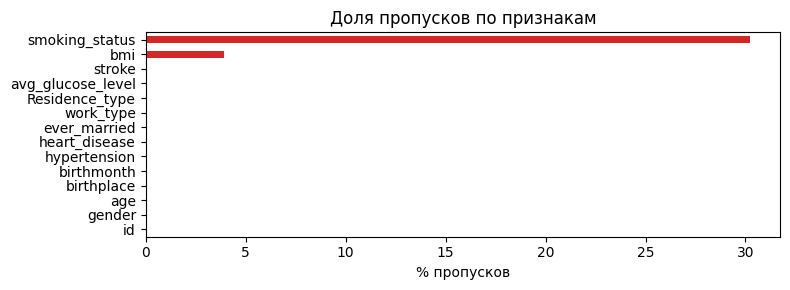

In [5]:
missing = pd.DataFrame({'пропусков': df.isna().sum(),
                        'доля, %': (df.isna().mean() * 100).round(2)})
display(missing[missing['пропусков'] > 0])

fig, ax = plt.subplots(figsize=(8, 3))
(df.isna().mean() * 100).sort_values().plot.barh(ax=ax, color='tab:red')
ax.set_xlabel('% пропусков'); ax.set_title('Доля пропусков по признакам')
plt.tight_layout(); plt.show()

Пропуски есть в двух признаках: `bmi` (~3.9%) и `smoking_status` (~30%). Для `smoking_status` пропуск —
это, по сути, отдельная категория «неизвестно» (в т.ч. у детей), поэтому заменим его на `Unknown`.
`bmi` заполним медианой (по обучающей выборке).

### 2.2 Описательная статистика

In [6]:
df[num_features + bin_features + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,5110.0,43.23,22.61,0.08,25.00,45.00,61.00,82.00
avg_glucose_level,5110.0,106.15,45.28,55.12,77.24,91.88,114.09,271.74
bmi,4909.0,28.89,7.85,10.30,23.50,28.10,33.10,97.60
hypertension,5110.0,0.10,0.30,0.00,0.00,0.00,0.00,1.00
heart_disease,5110.0,0.05,0.23,0.00,0.00,0.00,0.00,1.00
stroke,5110.0,0.05,0.22,0.00,0.00,0.00,0.00,1.00


In [7]:
for c in cat_features:
    print(c, '->', df[c].nunique(), 'уникальных:', dict(df[c].value_counts(dropna=False).head(8)))

gender -> 3 уникальных: {'Female': 2994, 'Male': 2115, 'Other': 1}
birthplace -> 50 уникальных: {'Rio de Janeiro': 122, 'Buenos Aires': 120, 'Ho Chi Minh City': 120, 'Tianjin': 117, 'Kolkata': 115, 'Seoul': 114, 'Delhi': 113, 'Hong Kong': 113}
birthmonth -> 12 уникальных: {'Oct': 469, 'Jul': 447, 'Apr': 446, 'Jan': 433, 'May': 427, 'Jun': 426, 'Aug': 425, 'Dec': 423}
ever_married -> 2 уникальных: {'Yes': 3353, 'No': 1757}
work_type -> 5 уникальных: {'Private': 2925, 'Self-employed': 819, 'children': 687, 'Govt_job': 657, 'Never_worked': 22}
Residence_type -> 2 уникальных: {'Urban': 2596, 'Rural': 2514}
smoking_status -> 3 уникальных: {'never smoked': 1892, nan: 1544, 'formerly smoked': 885, 'smokes': 789}


### 2.3 Распределение целевой переменной

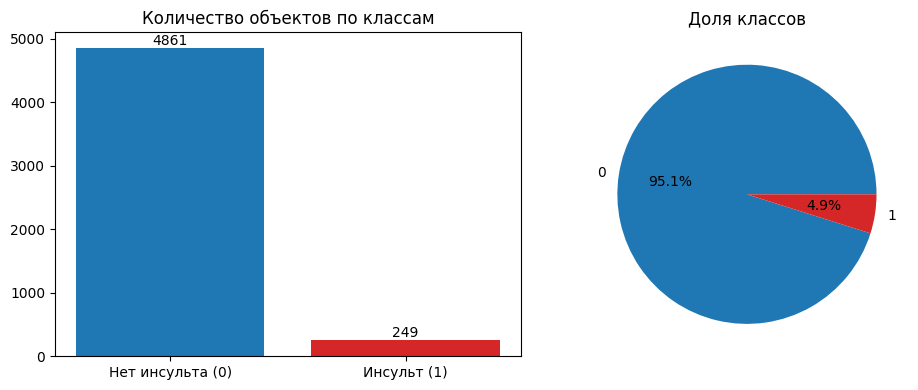

Соотношение классов ≈ 1 : 19.5


In [8]:
vc = df[TARGET].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].bar(['Нет инсульта (0)', 'Инсульт (1)'], vc.values, color=['tab:blue', 'tab:red'])
for i, v in enumerate(vc.values):
    ax[0].text(i, v, str(v), ha='center', va='bottom')
ax[0].set_title('Количество объектов по классам')
ax[1].pie(vc.values, labels=['0', '1'], autopct='%1.1f%%', colors=['tab:blue', 'tab:red'])
ax[1].set_title('Доля классов')
plt.tight_layout(); plt.show()
print(f'Соотношение классов ≈ 1 : {vc[0] / vc[1]:.1f}')

Классы **сильно несбалансированы**: инсульт только у ~4.9% пациентов. Значит, accuracy — плохая метрика
(модель «всегда 0» даст ~95%), будем смотреть на ROC-AUC, recall, F1 и balanced accuracy, а обучающую выборку сбалансируем.

### 2.4 Распределение числовых признаков

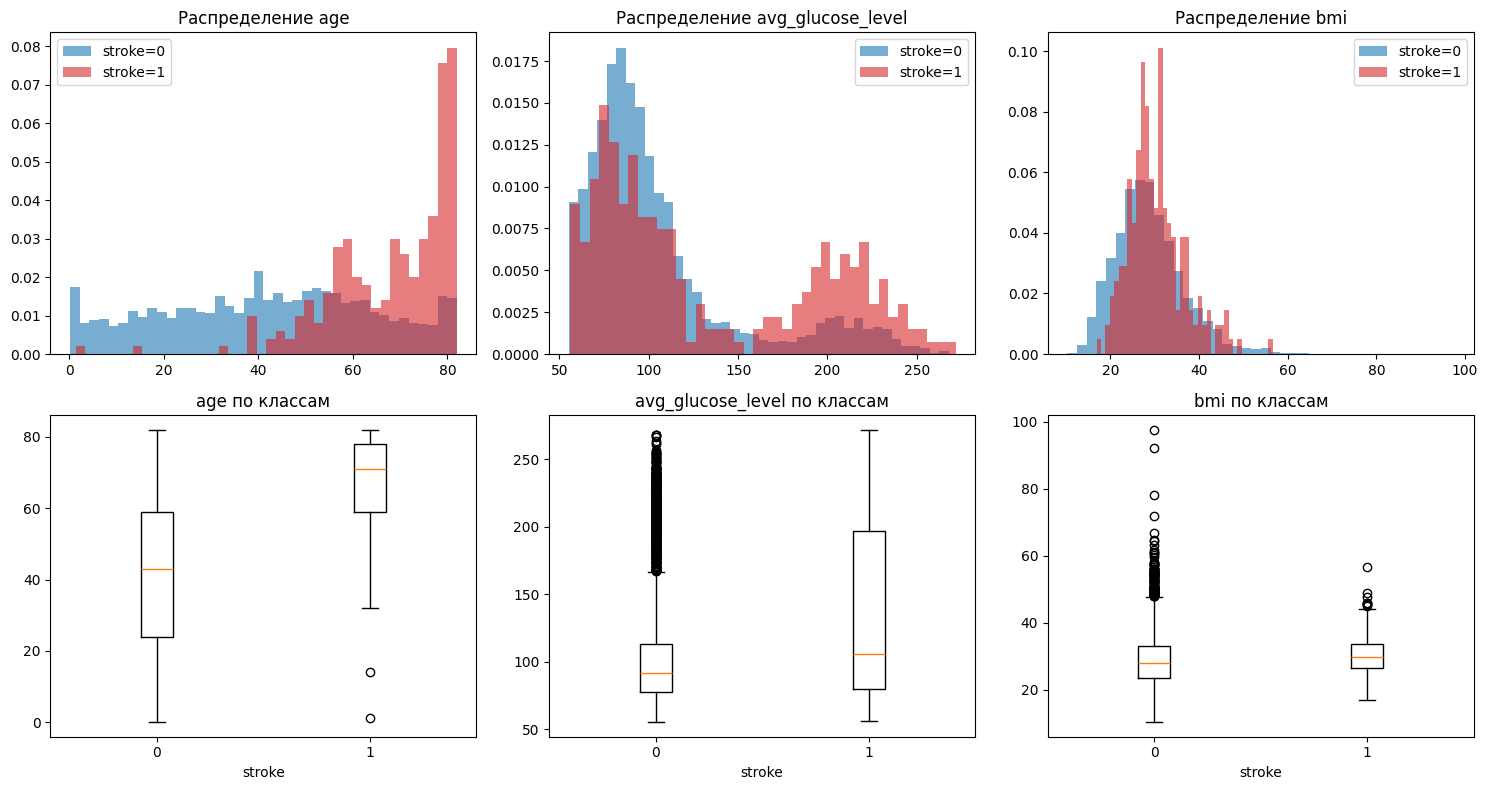

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, c in enumerate(num_features):
    ax = axes[0, i]
    ax.hist(df.loc[df[TARGET] == 0, c].dropna(), bins=40, alpha=0.6, density=True, label='stroke=0')
    ax.hist(df.loc[df[TARGET] == 1, c].dropna(), bins=40, alpha=0.6, density=True, label='stroke=1', color='tab:red')
    ax.set_title(f'Распределение {c}'); ax.legend()
    ax = axes[1, i]
    ax.boxplot([df.loc[df[TARGET] == k, c].dropna() for k in (0, 1)], labels=['0', '1'])
    ax.set_title(f'{c} по классам'); ax.set_xlabel('stroke')
plt.tight_layout(); plt.show()

* `age` — самый информативный признак: инсульты почти всегда у людей старше ~40 лет.
* `avg_glucose_level` — бимодальное распределение, у класса 1 заметно больше доля высокой глюкозы (>150).
* `bmi` — распределение скошено вправо, есть выбросы (до ~98); различие между классами небольшое.

### 2.5 Категориальные и бинарные признаки: частоты и доля инсультов

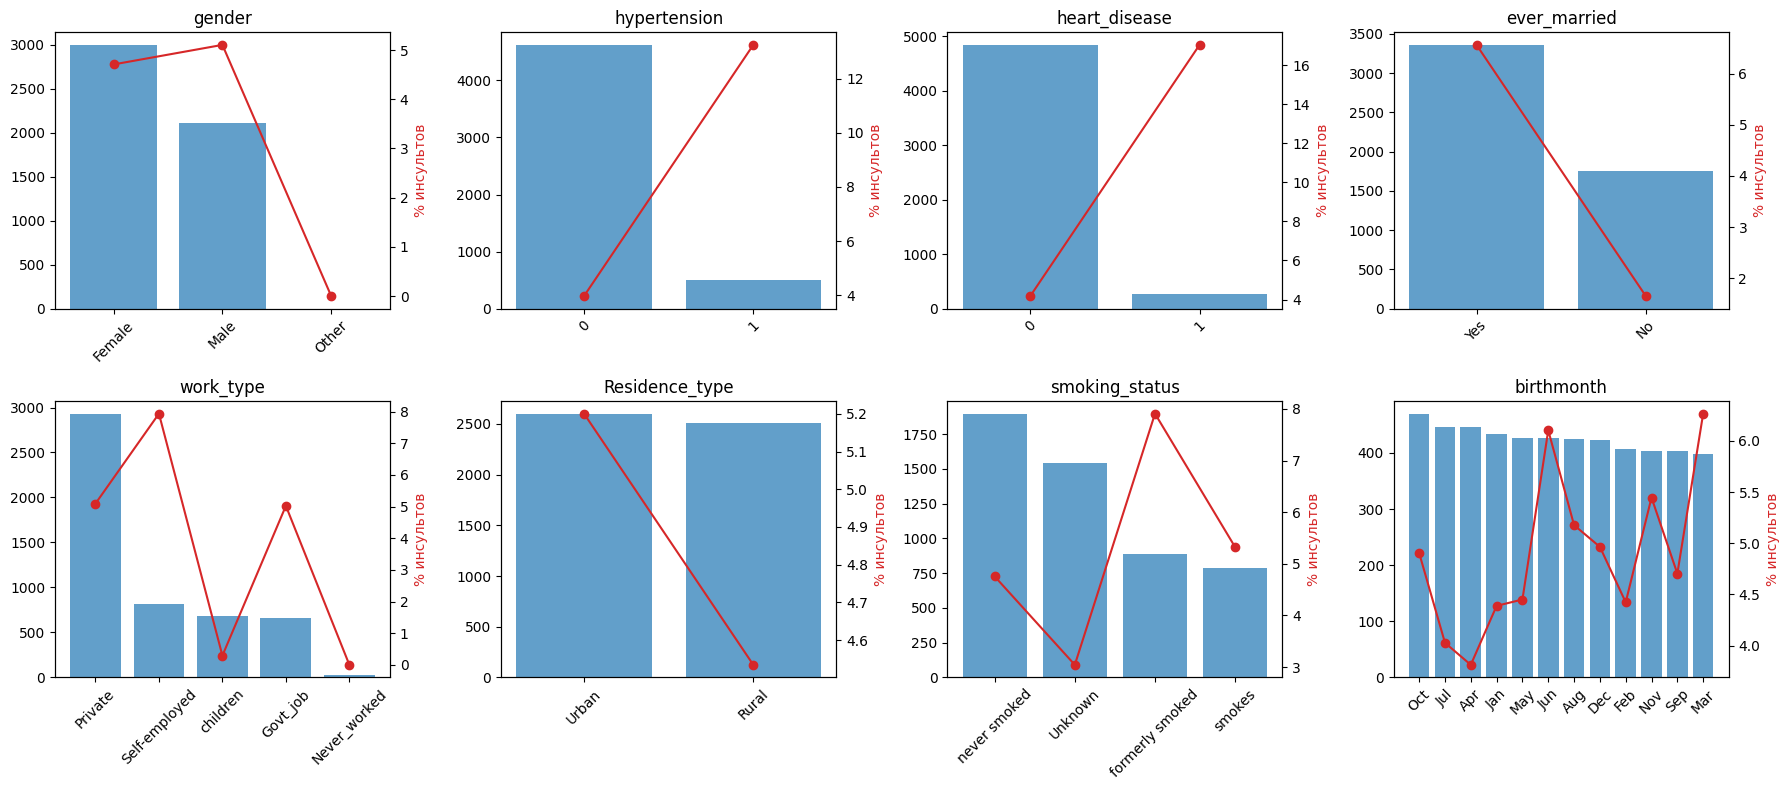

In [10]:
plot_cats = ['gender', 'hypertension', 'heart_disease', 'ever_married',
             'work_type', 'Residence_type', 'smoking_status', 'birthmonth']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), plot_cats):
    s = df[c].fillna('Unknown').astype(str)
    counts = s.value_counts()
    rate = df.groupby(s)[TARGET].mean().reindex(counts.index) * 100
    ax.bar(counts.index, counts.values, color='tab:blue', alpha=0.7)
    ax.set_title(c); ax.tick_params(axis='x', rotation=45)
    ax2 = ax.twinx()
    ax2.plot(counts.index, rate.values, 'o-', color='tab:red')
    ax2.set_ylabel('% инсультов', color='tab:red')
plt.tight_layout(); plt.show()

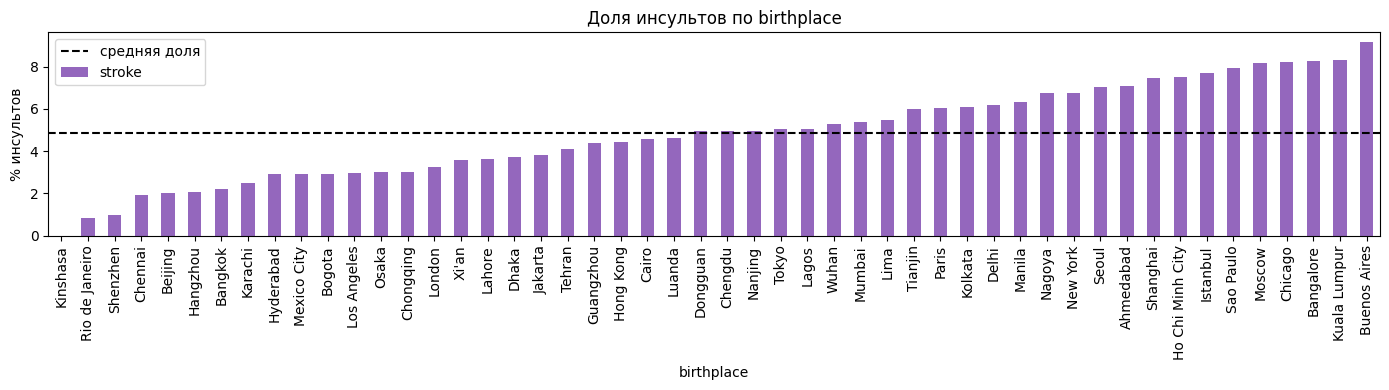

In [11]:
# Доля инсультов по городу рождения
rate_city = df.groupby('birthplace')[TARGET].mean().sort_values() * 100
fig, ax = plt.subplots(figsize=(14, 4))
rate_city.plot.bar(ax=ax, color='tab:purple')
ax.axhline(df[TARGET].mean() * 100, color='k', ls='--', label='средняя доля')
ax.set_ylabel('% инсультов'); ax.set_title('Доля инсультов по birthplace'); ax.legend()
plt.tight_layout(); plt.show()

### 2.6 Статистическая значимость признаков
Для категориальных признаков — критерий хи-квадрат, для числовых — критерий Манна–Уитни.

In [12]:
rows = []
for c in cat_features + bin_features:
    table = pd.crosstab(df[c].fillna('Unknown'), df[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(table)
    rows.append((c, 'хи-квадрат', p))
for c in num_features:
    x = df[c].dropna()
    p = stats.mannwhitneyu(x[df[TARGET] == 0], x[df[TARGET] == 1]).pvalue
    rows.append((c, 'Манна–Уитни', p))
sig = pd.DataFrame(rows, columns=['признак', 'тест', 'p-value']).sort_values('p-value')
sig['значим (p<0.05)'] = sig['p-value'] < 0.05
sig

,признак,тест,p-value,значим (p<0.05)
9,age,Манна–Уитни,3.726635e-71,True
8,heart_disease,хи-квадрат,2.088785e-21,True
7,hypertension,хи-квадрат,1.661622e-19,True
3,ever_married,хи-квадрат,1.638902e-14,True
4,work_type,хи-квадрат,5.397708e-10,True
10,avg_glucose_level,Манна–Уитни,3.640367e-09,True
6,smoking_status,хи-квадрат,2.085400e-06,True
11,bmi,Манна–Уитни,1.026429e-04,True
1,birthplace,хи-квадрат,2.750451e-01,False
5,Residence_type,хи-квадрат,2.983317e-01,False


Признаки `birthplace` (50 городов) и `birthmonth` статистически **не связаны** с инсультом (p-value ≫ 0.05),
доли инсультов по ним колеблются случайно вокруг среднего. Они только добавят шум и ~60 dummy-столбцов,
поэтому их удалим. `gender` и `Residence_type` тоже слабые, но оставим их — это всего по одному столбцу.

### 2.7 Корреляции

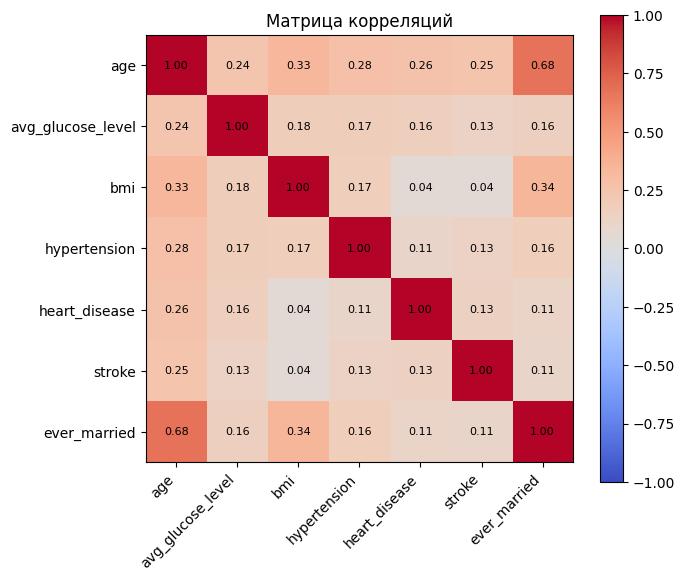

In [13]:
corr_df = df[num_features + bin_features + [TARGET]].copy()
corr_df['ever_married'] = (df['ever_married'] == 'Yes').astype(int)
corr = corr_df.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=8)
fig.colorbar(im); ax.set_title('Матрица корреляций')
plt.tight_layout(); plt.show()

Сильнее всего с `stroke` коррелирует `age` (~0.25), затем `heart_disease`, `avg_glucose_level`, `hypertension`.
`ever_married` сильно коррелирует с возрастом (~0.68). Мультиколлинеарности, требующей удаления признаков, нет.

## 3. Очистка и подготовка данных
### 3.1 Очистка

In [14]:
data = df.copy()
data = data.drop(columns=['id', 'birthplace', 'birthmonth'])   # идентификатор и неинформативные признаки
data = data[data['gender'] != 'Other']                          # единственный объект — шум для OHE
data['smoking_status'] = data['smoking_status'].fillna('Unknown')
print('После очистки:', data.shape)
print('Пропуски:', data.isna().sum()[data.isna().sum() > 0].to_dict())

После очистки: (5109, 11)
Пропуски: {'bmi': 201}


Выбросы `bmi` (> 60) встречаются единично; так как модели (кроме NB и LogReg) к ним устойчивы,
а для линейных моделей используется стандартизация, просто ограничим значения 1-м и 99-м перцентилем
(границы вычисляем по train, чтобы не было утечки).

### 3.2 Разбиение на обучающую и тестовую выборки
Стратифицированное разбиение 80/20, чтобы доля инсультов была одинаковой. Тест не балансируем — он
должен отражать реальное распределение.

In [15]:
X = data.drop(columns=TARGET)
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('train:', X_train.shape, 'доля 1 =', round(y_train.mean(), 4))
print('test :', X_test.shape, 'доля 1 =', round(y_test.mean(), 4))

lo, hi = X_train['bmi'].quantile([0.01, 0.99])
X_train['bmi'] = X_train['bmi'].clip(lo, hi)
X_test['bmi'] = X_test['bmi'].clip(lo, hi)
print(f'bmi ограничен диапазоном [{lo:.1f}, {hi:.1f}]')

train: (4087, 10) доля 1 = 0.0487
test : (1022, 10) доля 1 = 0.0489
bmi ограничен диапазоном [15.1, 53.4]


### 3.3 Кодирование признаков
* числовые: заполнение пропусков медианой + `StandardScaler`;
* бинарные (0/1): без изменений;
* категориальные: One-Hot Encoding.

Препроцессор обучается **только на train**.

In [16]:
num_cols = ['age', 'avg_glucose_level', 'bmi']
bin_cols = ['hypertension', 'heart_disease']
cat_cols = ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                      ('scaler', StandardScaler())]), num_cols),
    ('bin', 'passthrough', bin_cols),
    ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols),
])

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()
print('Признаков после кодирования:', X_train_enc.shape[1])
print(list(feature_names))

Признаков после кодирования: 17
['num__age', 'num__avg_glucose_level', 'num__bmi', 'bin__hypertension', 'bin__heart_disease', 'cat__gender_Male', 'cat__ever_married_Yes', 'cat__work_type_Govt_job', 'cat__work_type_Never_worked', 'cat__work_type_Private', 'cat__work_type_Self-employed', 'cat__work_type_children', 'cat__Residence_type_Urban', 'cat__smoking_status_Unknown', 'cat__smoking_status_formerly smoked', 'cat__smoking_status_never smoked', 'cat__smoking_status_smokes']


### 3.4 Балансировка классов
`imblearn` не используем — реализуем случайный oversampling миноритарного класса через `sklearn.utils.resample`.
Балансируем **только обучающую выборку** (иначе дубликаты попадут в тест и метрики будут завышены).

До балансировки:    [3888  199]
После балансировки: [3888 3888]


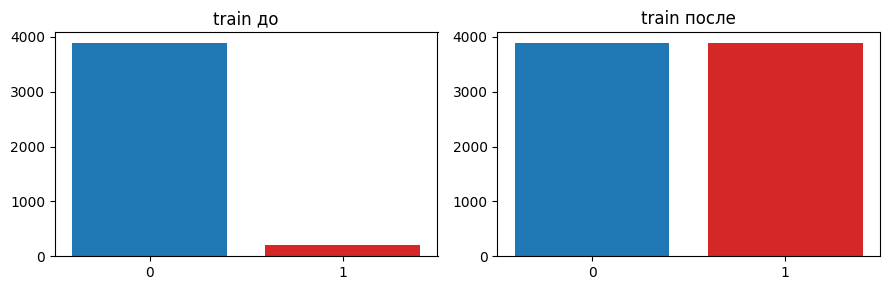

In [17]:
def oversample(X_arr, y_arr, random_state=RANDOM_STATE):
    y_arr = np.asarray(y_arr)
    X_min, X_maj = X_arr[y_arr == 1], X_arr[y_arr == 0]
    X_min_up = resample(X_min, replace=True, n_samples=len(X_maj), random_state=random_state)
    X_bal = np.vstack([X_maj, X_min_up])
    y_bal = np.hstack([np.zeros(len(X_maj)), np.ones(len(X_min_up))]).astype(int)
    idx = np.random.RandomState(random_state).permutation(len(y_bal))
    return X_bal[idx], y_bal[idx]

X_train_bal, y_train_bal = oversample(X_train_enc, y_train)
print('До балансировки:   ', np.bincount(y_train))
print('После балансировки:', np.bincount(y_train_bal))

fig, ax = plt.subplots(1, 2, figsize=(9, 3))
ax[0].bar(['0', '1'], np.bincount(y_train), color=['tab:blue', 'tab:red']); ax[0].set_title('train до')
ax[1].bar(['0', '1'], np.bincount(y_train_bal), color=['tab:blue', 'tab:red']); ax[1].set_title('train после')
plt.tight_layout(); plt.show()

## 4. Классические ML-модели
Обучаем на сбалансированном train, оцениваем на исходном (несбалансированном) test.
Для дерева, леса и бустинга ограничиваем глубину / размер листьев, т.к. при oversampling
дубликаты миноритарного класса легко «заучиваются».

In [18]:
results = {}
probas = {}

def evaluate(name, y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    results[name] = {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced acc': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall': recall_score(y_true, y_pred),
        'F1': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
    }
    probas[name] = y_prob
    print(f'===== {name} =====')
    print(classification_report(y_true, y_pred, digits=3, zero_division=0))

models = {
    'Naive Bayes': GaussianNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10,
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=200, max_depth=3, learning_rate=0.05,
                                                    subsample=0.8, random_state=RANDOM_STATE),
}

for name, model in models.items():
    model.fit(X_train_bal, y_train_bal)
    evaluate(name, y_test, model.predict_proba(X_test_enc)[:, 1])

===== Naive Bayes =====
              precision    recall  f1-score   support

           0      0.996     0.273     0.428       972
           1      0.065     0.980     0.122        50

    accuracy                          0.307      1022
   macro avg      0.531     0.626     0.275      1022
weighted avg      0.951     0.307     0.413      1022

===== Logistic Regression =====
              precision    recall  f1-score   support

           0      0.986     0.734     0.841       972
           1      0.134     0.800     0.229        50

    accuracy                          0.737      1022
   macro avg      0.560     0.767     0.535      1022
weighted avg      0.944     0.737     0.811      1022

===== Decision Tree =====
              precision    recall  f1-score   support

           0      0.982     0.821     0.894       972
           1      0.167     0.700     0.270        50

    accuracy                          0.815      1022
   macro avg      0.575     0.760     0.582   

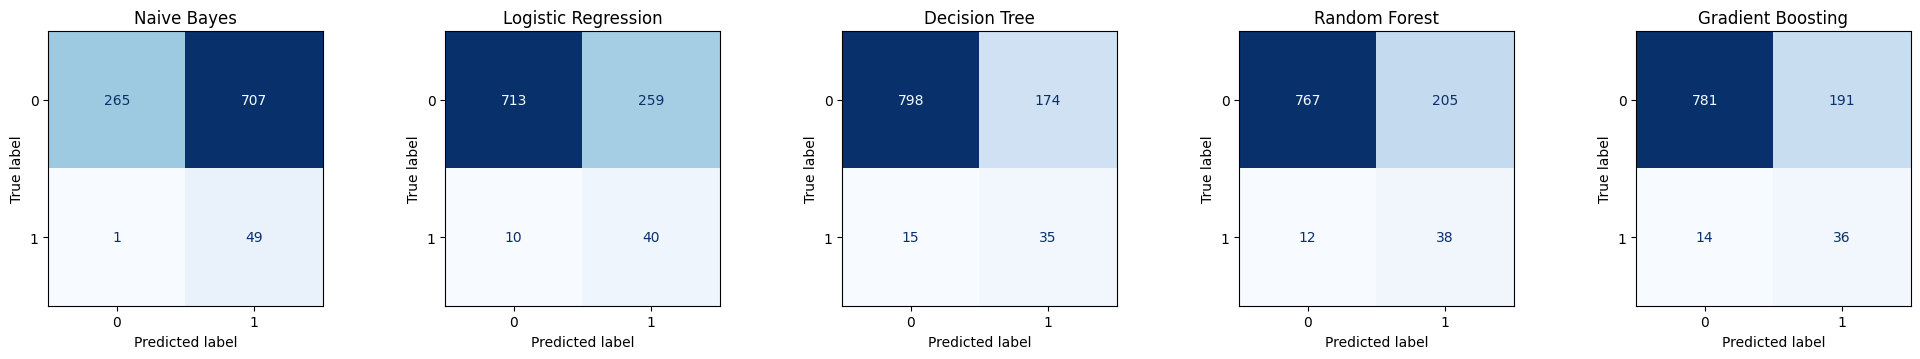

In [19]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.6))
for ax, (name, model) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, model.predict(X_test_enc))
    ConfusionMatrixDisplay(cm, display_labels=['0', '1']).plot(ax=ax, colorbar=False, cmap='Blues')
    ax.set_title(name)
plt.tight_layout(); plt.show()

### 4.1 Кросс-валидация
Чтобы оценка не зависела от одного разбиения, сделаем 5-fold стратифицированную CV на train
(балансировка — внутри каждого фолда, по ROC-AUC).

In [20]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_tr_np, y_tr_np = X_train_enc, y_train.values
cv_rows = []
for name, model in models.items():
    scores = []
    for tr_idx, va_idx in skf.split(X_tr_np, y_tr_np):
        Xb, yb = oversample(X_tr_np[tr_idx], y_tr_np[tr_idx])
        m = type(model)(**model.get_params()).fit(Xb, yb)
        scores.append(roc_auc_score(y_tr_np[va_idx], m.predict_proba(X_tr_np[va_idx])[:, 1]))
    cv_rows.append((name, np.mean(scores), np.std(scores)))
pd.DataFrame(cv_rows, columns=['модель', 'CV ROC-AUC mean', 'std']).round(4)

,модель,CV ROC-AUC mean,std
0,Naive Bayes,0.8075,0.0178
1,Logistic Regression,0.8387,0.0199
2,Decision Tree,0.7553,0.0330
3,Random Forest,0.8284,0.0285
4,Gradient Boosting,0.8143,0.0291


### 4.2 Важность признаков

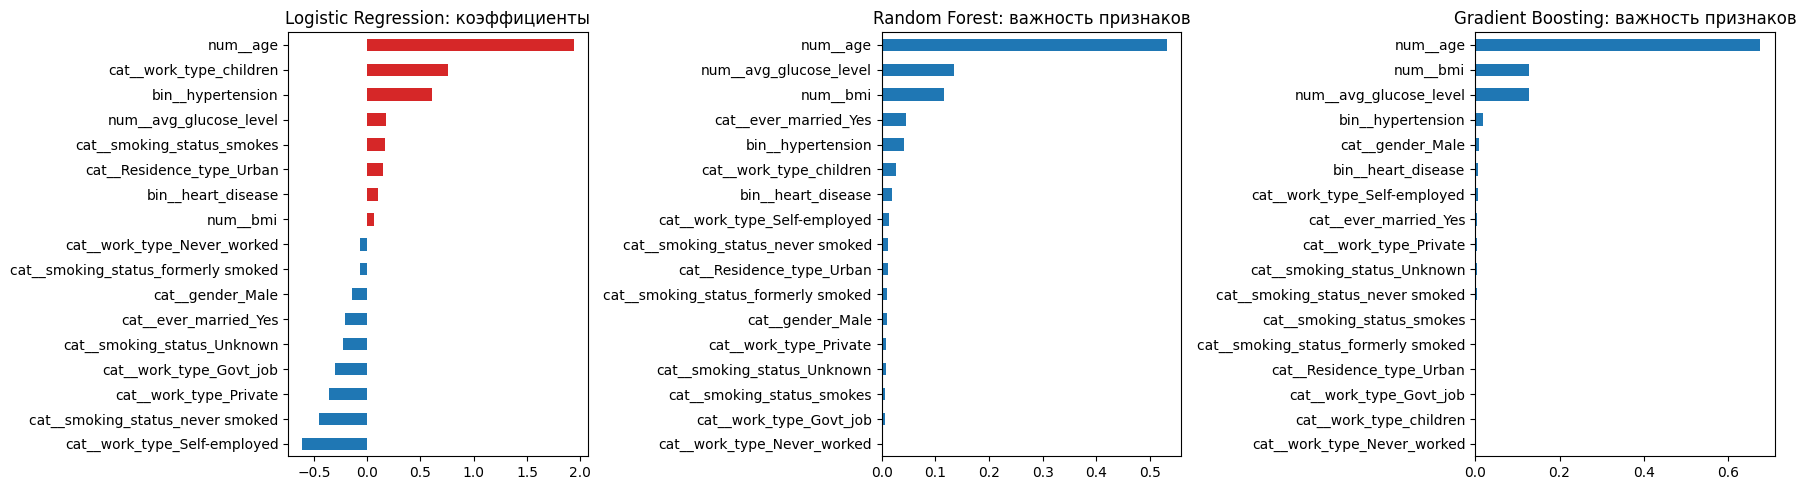

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
coef = pd.Series(models['Logistic Regression'].coef_[0], index=feature_names).sort_values()
coef.plot.barh(ax=axes[0], color=np.where(coef > 0, 'tab:red', 'tab:blue'))
axes[0].set_title('Logistic Regression: коэффициенты')
for ax, name in zip(axes[1:], ['Random Forest', 'Gradient Boosting']):
    pd.Series(models[name].feature_importances_, index=feature_names).sort_values().plot.barh(ax=ax)
    ax.set_title(f'{name}: важность признаков')
plt.tight_layout(); plt.show()

Все модели сходятся: главный фактор — **возраст**, далее уровень глюкозы, гипертония, болезни сердца и `bmi`.

## 5. Нейронная сеть
Небольшой полносвязный MLP на Keras: 2 скрытых слоя (32 и 16 нейронов, ReLU), Dropout и L2-регуляризация,
выход — сигмоида. Из train выделяем валидационную выборку (до балансировки) для ранней остановки.

In [22]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
tf.random.set_seed(RANDOM_STATE)
keras.utils.set_random_seed(RANDOM_STATE)

X_tr_nn, X_val_nn, y_tr_nn, y_val_nn = train_test_split(
    X_train_enc, y_train.values, test_size=0.2, stratify=y_train, random_state=RANDOM_STATE)
X_tr_nn, y_tr_nn = oversample(X_tr_nn, y_tr_nn)
X_tr_nn, X_val_nn = X_tr_nn.astype('float32'), X_val_nn.astype('float32')

def build_model(n_features):
    model = keras.Sequential([
        keras.Input(shape=(n_features,)),
        layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
        layers.Dropout(0.3),
        layers.Dense(16, activation='relu', kernel_regularizer=regularizers.l2(1e-3)),
        layers.Dropout(0.3),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(name='auc'), keras.metrics.Recall(name='recall')])
    return model

nn = build_model(X_tr_nn.shape[1])
nn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

Обучение остановлено на эпохе 17 | лучший val AUC = 0.8771


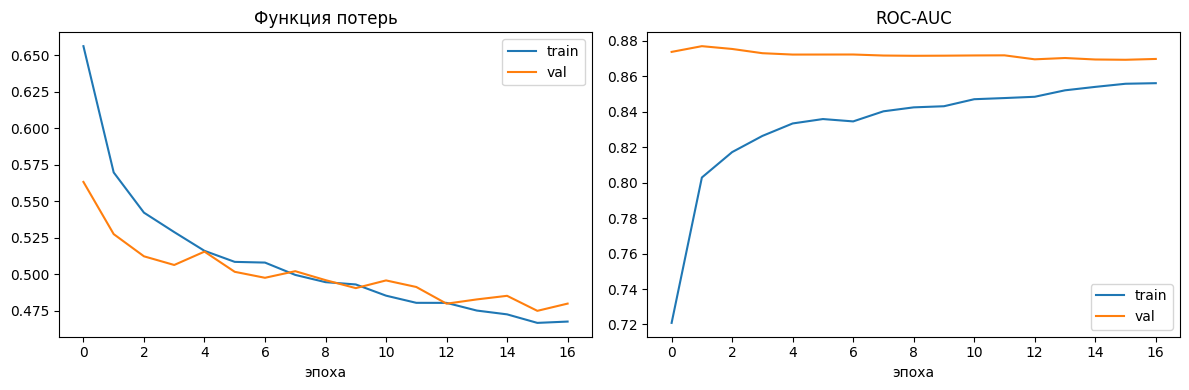

In [23]:
early_stop = keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=15,
                                           restore_best_weights=True)
history = nn.fit(X_tr_nn, y_tr_nn, validation_data=(X_val_nn, y_val_nn),
                 epochs=200, batch_size=64, callbacks=[early_stop], verbose=0)
print('Обучение остановлено на эпохе', len(history.history['loss']),
      '| лучший val AUC =', round(max(history.history['val_auc']), 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history['loss'], label='train'); ax[0].plot(history.history['val_loss'], label='val')
ax[0].set_title('Функция потерь'); ax[0].set_xlabel('эпоха'); ax[0].legend()
ax[1].plot(history.history['auc'], label='train'); ax[1].plot(history.history['val_auc'], label='val')
ax[1].set_title('ROC-AUC'); ax[1].set_xlabel('эпоха'); ax[1].legend()
plt.tight_layout(); plt.show()

===== Neural Network (MLP) =====
              precision    recall  f1-score   support

           0      0.986     0.668     0.796       972
           1      0.113     0.820     0.198        50

    accuracy                          0.675      1022
   macro avg      0.549     0.744     0.497      1022
weighted avg      0.944     0.675     0.767      1022



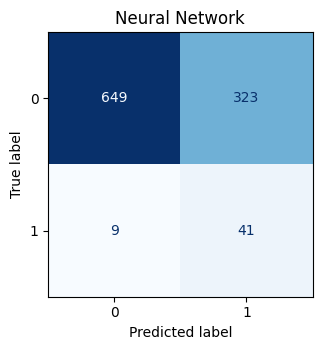

In [24]:
nn_prob = nn.predict(X_test_enc.astype('float32'), verbose=0).ravel()
evaluate('Neural Network (MLP)', y_test, nn_prob)

fig, ax = plt.subplots(figsize=(4, 3.6))
ConfusionMatrixDisplay(confusion_matrix(y_test, (nn_prob >= 0.5).astype(int)),
                       display_labels=['0', '1']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title('Neural Network'); plt.tight_layout(); plt.show()

## 6. Сравнение моделей

,Accuracy,Balanced acc,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.737,0.767,0.134,0.800,0.229,0.839
Random Forest,0.788,0.775,0.156,0.760,0.259,0.830
Neural Network (MLP),0.675,0.744,0.113,0.820,0.198,0.825
Gradient Boosting,0.799,0.762,0.159,0.720,0.260,0.818
Decision Tree,0.815,0.760,0.167,0.700,0.270,0.816
Naive Bayes,0.307,0.626,0.065,0.980,0.122,0.794


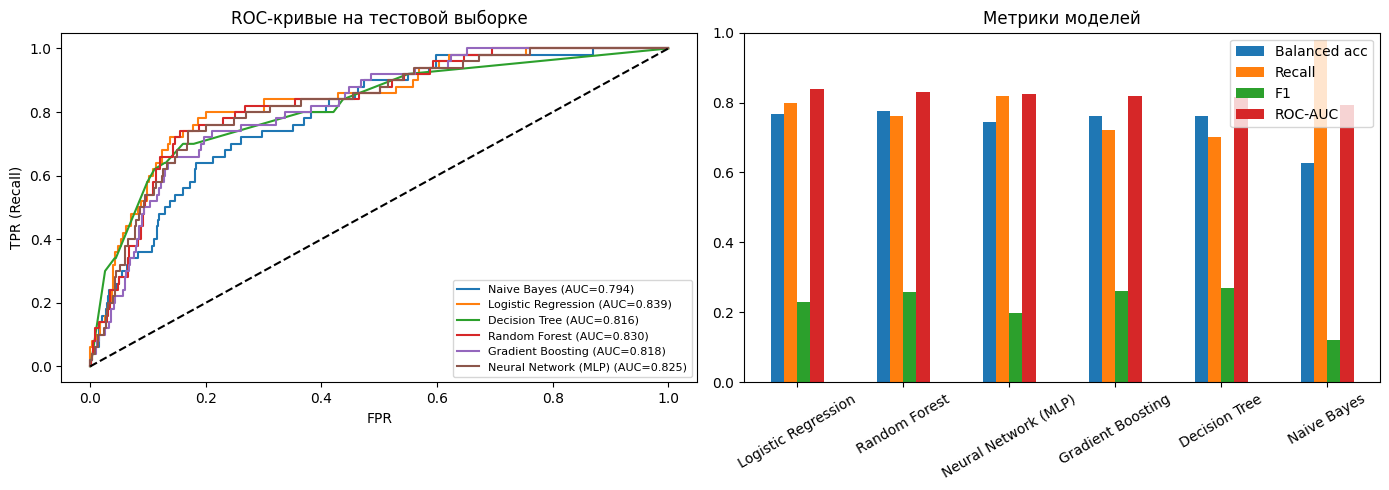

In [25]:
res = pd.DataFrame(results).T.sort_values('ROC-AUC', ascending=False)
display(res.style.format('{:.3f}').background_gradient(cmap='Greens', subset=['Balanced acc', 'Recall', 'F1', 'ROC-AUC']))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, p in probas.items():
    fpr, tpr, _ = roc_curve(y_test, p)
    ax[0].plot(fpr, tpr, label=f'{name} (AUC={roc_auc_score(y_test, p):.3f})')
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR (Recall)')
ax[0].set_title('ROC-кривые на тестовой выборке'); ax[0].legend(fontsize=8)
res[['Balanced acc', 'Recall', 'F1', 'ROC-AUC']].plot.bar(ax=ax[1])
ax[1].set_title('Метрики моделей'); ax[1].tick_params(axis='x', rotation=30); ax[1].set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 7. Выводы

In [26]:
best = res['ROC-AUC'].idxmax()
print(f'Лучшая модель по ROC-AUC: {best} ({res.loc[best, "ROC-AUC"]:.3f})')
print(f'Лучшая модель по Recall:  {res["Recall"].idxmax()} ({res["Recall"].max():.3f})')
print(f'Лучшая модель по F1:      {res["F1"].idxmax()} ({res["F1"].max():.3f})')

Лучшая модель по ROC-AUC: Logistic Regression (0.839)
Лучшая модель по Recall:  Naive Bayes (0.980)
Лучшая модель по F1:      Decision Tree (0.270)


1. **Данные**: 5110 пациентов, 12 признаков (+ `id`), целевой `stroke`. Пропуски в `bmi` (~4%) и `smoking_status` (~30%).
   Классы сильно несбалансированы (≈1:19).
2. **Анализ** показал, что ключевые факторы риска — возраст, уровень глюкозы, гипертония и болезни сердца.
   Признаки `birthplace` и `birthmonth` статистически не связаны с инсультом и были удалены.
3. **Подготовка**: удалены `id` и неинформативные признаки, пропуски `smoking_status` → `Unknown`, `bmi` → медиана,
   выбросы `bmi` ограничены перцентилями, стратифицированное разбиение 80/20, стандартизация + One-Hot,
   oversampling миноритарного класса только на train.
4. **Модели** (ROC-AUC на тесте): логистическая регрессия — 0.839, случайный лес — 0.830, бустинг — 0.818,
   дерево решений — 0.816, наивный Байес — 0.794. По 5-fold CV картина та же: лучше всех логистическая регрессия (0.839)
   и случайный лес (0.828), хуже всех дерево решений (0.755 ± 0.033 — высокая дисперсия одиночного дерева).
   Наивный Байес находит 98% инсультов, но почти всех относит к классу 1 (accuracy 0.31) — сказывается допущение
   о независимости и нормальности признаков.
5. **Нейросеть** (MLP 32-16-1, ~1.1 тыс. параметров) даёт ROC-AUC 0.825 и recall 0.82 — на уровне классических моделей.
   На небольшом табличном датасете с простыми зависимостями нейросеть выигрыша не даёт; оптимальна
   простая и интерпретируемая логистическая регрессия.
6. Из-за дисбаланса precision по классу 1 низкий при высоком recall — для медицинского скрининга это приемлемо:
   пропустить инсульт хуже, чем отправить здорового на дообследование. Порог классификации можно сдвигать
   в зависимости от требуемого баланса precision/recall.